# Binary word-frequency delta signal

Load and plot the precomputed low-minus-high Zipf-frequency delta signal for one subject and run. The signal is stored under `RESULTS_DIR / 'binary_frequency' / subject / run_prefix / 'meg'` by `processing/run_binary_delta_activation.py`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import mne

project_root = next(
    (directory for directory in (Path.cwd(), *Path.cwd().parents)
     if (directory / 'config.py').is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Could not locate config.py from the current directory')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from config import RESULTS_DIR

In [2]:
def add_rms_axis(ax, times_ms, signal, band=0.2):
    """Draw the across-channel RMS on a right-hand axis, confined to the bottom `band` of the plot."""
    rms = np.sqrt(np.mean(signal**2, axis=0))
    low, high = ax.get_ylim()
    ax.set_ylim(low - (high - low) * band / (1 - band), high)  # reserve the bottom band for the RMS
    rms_ax = ax.twinx()
    rms_ax.fill_between(times_ms, rms, color='grey', alpha=0.4)
    rms_ax.plot(times_ms, rms, color='black', linewidth=1)
    rms_ax.set_ylim(0, rms.max() / band)
    rms_ax.set_yticks([tick for tick in rms_ax.get_yticks() if 0 <= tick <= rms.max()])
    rms_ax.set_ylabel('RMS across channels (fT/cm)')
    return rms_ax

In [3]:
subject = 'sub-01'
run = 'run-01'
run_prefix = f'{subject}_ses-01_task-listen_{run}'

signal_path = (
    RESULTS_DIR
    / 'binary_frequency'
    / subject
    / run_prefix
    / 'meg'
    / f'{run_prefix}_low-minus-high_binary_frequency.npz'
)
if not signal_path.is_file():
    raise FileNotFoundError(
        f'Delta signal not found: {signal_path}. '
        'Run processing/run_binary_delta_activation.py first.'
    )

with np.load(signal_path, allow_pickle=False) as result:
    signal = result['signal'] * 1e13 
    channel_names = result['channel_names']
    times = result['times']
    low_word_count = int(result['low_word_count'].item())
    high_word_count = int(result['high_word_count'].item())

In [4]:
print(f'File: {signal_path}')
print(f'Signal shape (channels, samples): {signal.shape}')
print(f'Channels: {len(channel_names)}')
print(f'Words: {low_word_count} low-frequency, {high_word_count} high-frequency')
print(f'Time range: {times[0] * 1000:.1f} to {times[-1] * 1000:.1f} ms')

File: /mnt/sda/data-output/phd/Pallier2025_results/binary_frequency/sub-01/sub-01_ses-01_task-listen_run-01/meg/sub-01_ses-01_task-listen_run-01_low-minus-high_binary_frequency.npz
Signal shape (channels, samples): (204, 1300)
Channels: 204
Words: 796 low-frequency, 818 high-frequency
Time range: -500.0 to 799.0 ms


In [5]:
# We only need this for meg.info
from meg import Meg
meg = Meg(run_prefix, filter=True, maxwell=True)

/home/felipe/git/phd/meg/meg.py:157: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  self.raw = mne.io.read_raw_fif(


Loaded bad-channel lists from /mnt/sda/data-output/phd/Pallier2025_results/preprocessing/sub-01/sub-01_ses-01_task-listen_run-01/meg/bad_channels.json.
Maxwell filtering started at 2026-10-18 17:49:41.
Maxwell filtering ended at 2026-10-18 17:50:07; elapsed 26.78 seconds.
Filtering gradiometer data (0.5–20 Hz) started at 2026-10-18 17:50:07.
Filtering ended at 2026-10-18 17:50:10; elapsed 2.75 seconds.


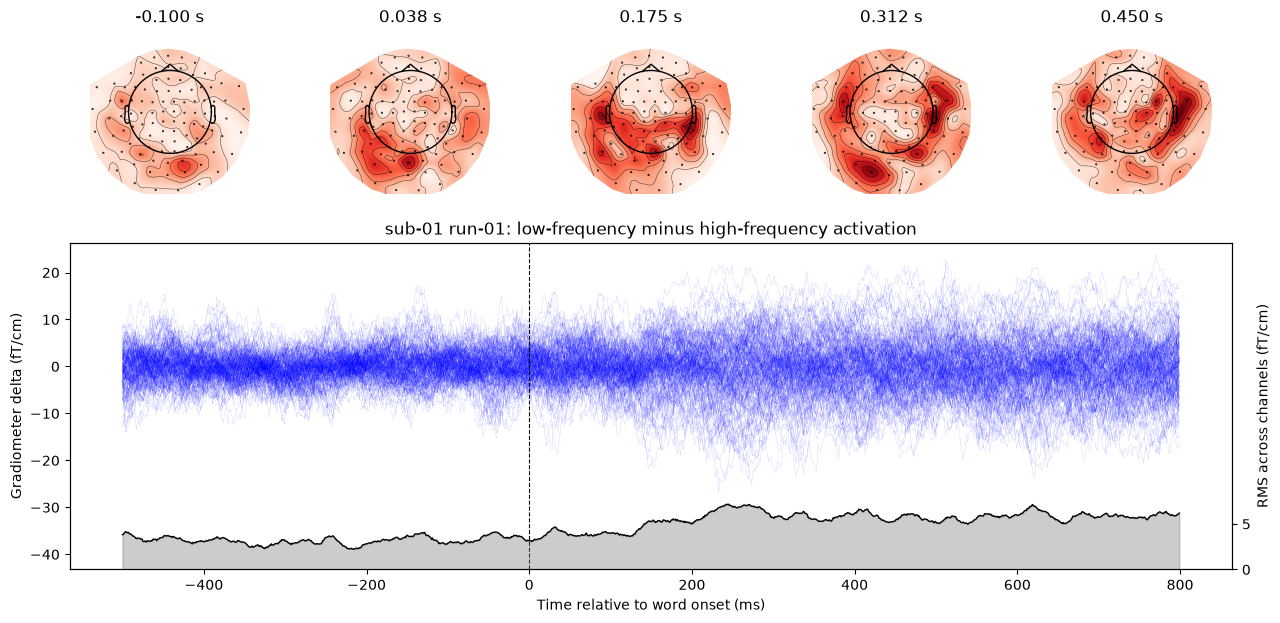

In [32]:
times_ms = times * 1000
before_ms = times_ms[0]

picks = mne.pick_types(meg.raw.info, meg="grad", exclude=[])
info = mne.pick_info(meg.raw.info, picks)

# Assumes data has the same channel order as picks
evoked = mne.EvokedArray(signal, info, tmin=before_ms / 1000)

fig = plt.figure(figsize=(15, 7))
gs = fig.add_gridspec(2, 5, height_ratios=[1, 2])

topo_axes = [fig.add_subplot(gs[0, i]) for i in range(5)]
ax = fig.add_subplot(gs[1, :])

evoked.plot_topomap(
    times=[-0.100, 0.038, 0.175, 0.312, 0.450],
    ch_type="grad",
    axes=topo_axes,
    cmap="Reds",
    colorbar=False,
    show=False,
)
ax.plot(times_ms, signal.T, color='blue', alpha=1, linewidth=0.05)
ax.axvline(0, color='k', linestyle='--', linewidth=0.8)
ax.set_xlabel('Time relative to word onset (ms)')
ax.set_ylabel('Gradiometer delta (fT/cm)')
ax.set_title(f'{subject} {run}: low-frequency minus high-frequency activation')
add_rms_axis(ax, times_ms, signal)
plt.show()

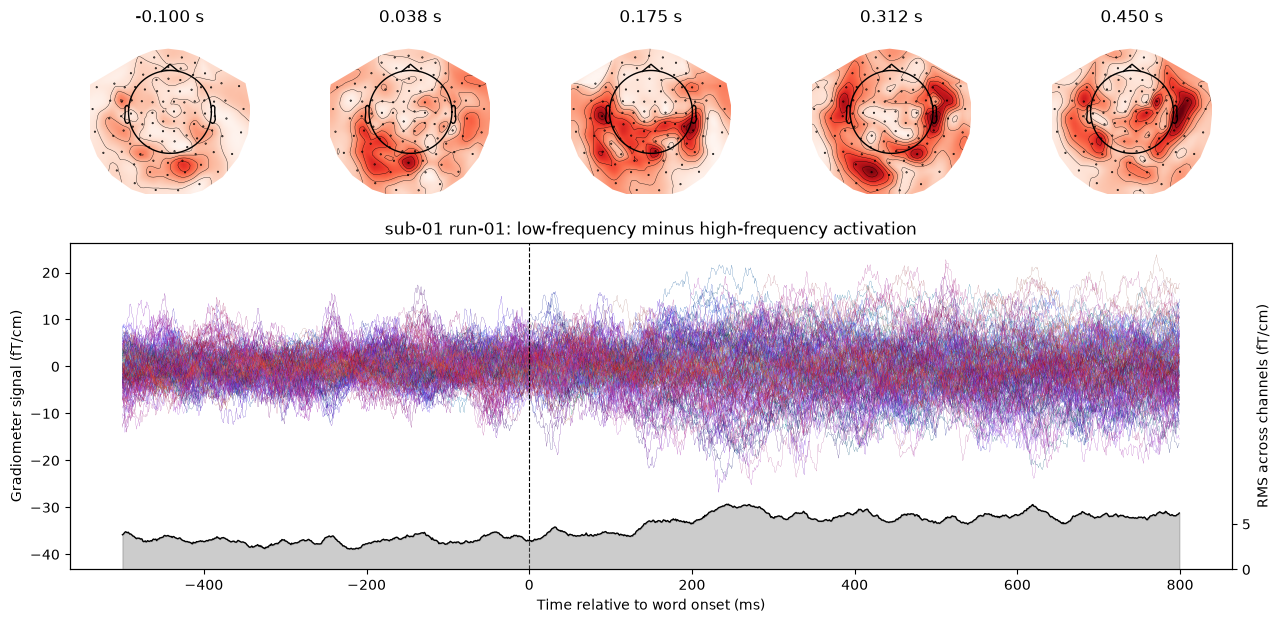

In [33]:
from mne.viz.evoked import _rgb
times_ms = times * 1000
before_ms = times_ms[0]

picks = mne.pick_types(meg.raw.info, meg="grad", exclude=[])
info = mne.pick_info(meg.raw.info, picks)

# Assumes data has the same channel order as picks
evoked = mne.EvokedArray(signal, info, tmin=before_ms / 1000)

fig = plt.figure(figsize=(15, 7))
gs = fig.add_gridspec(2, 5, height_ratios=[1, 2])

topo_axes = [fig.add_subplot(gs[0, i]) for i in range(5)]
ax = fig.add_subplot(gs[1, :])

evoked.plot_topomap(
    times=[-0.100, 0.038, 0.175, 0.312, 0.450],
    ch_type="grad",
    axes=topo_axes,
    cmap="Reds",
    colorbar=False,
    show=False,
)
ax.plot(times_ms, signal.T, color='blue', alpha=1, linewidth=0.05)
picks = mne.pick_types(meg.raw.info, meg="grad", exclude=[])
xyz = np.array([meg.raw.info["chs"][i]["loc"][:3] for i in picks])
colors = _rgb(*xyz.T)
assert len(colors) == signal.shape[0]
for sig, color in zip(signal, colors):
    ax.plot(times_ms, sig, color=color, alpha=1, linewidth=0.1)
ax.axvline(0, color='k', linestyle='--', linewidth=0.8)
ax.set_xlabel('Time relative to word onset (ms)')
ax.set_ylabel('Gradiometer signal (fT/cm)')
ax.set_title(f'{subject} {run}: low-frequency minus high-frequency activation')
add_rms_axis(ax, times_ms, signal)
plt.show()